# From genes to prognosis: predicting breast-cancer mortality from clinical and genomic data (METABRIC)

**Machine Learning 1 capstone, Tek-Up, ING-4 SDIA, 2026–2027**
**Team:** Oumaima Hafiane, Imen Hichri
**Notebook 02: Preprocessing & Feature Engineering (Phase 4)**

# 4. Preprocessing & Feature Engineering

## Objective
Turn the raw METABRIC table into clean, model-ready matrices **without data leakage**. This notebook applies the decisions written at the end of the EDA notebook (`01_eda.ipynb`, section 3.13). Figure numbering continues from the EDA (Fig. 1 to 11).

## Decisions taken in the EDA and where they are applied

| Finding in the EDA | Decision | Section |
|---|---|---|
| 1 patient without target, 1 "Breast Sarcoma" patient | Drop these two rows | 4.2 |
| Outcome columns and the identifier | Remove from the features (leakage) | 4.3 |
| Redundant columns (`er_status_measured_by_ihc`, `cancer_type_detailed`, `oncotree_code`, `cancer_type`) | Drop | 4.3 |
| Mutation columns are sparse text | Convert to 0/1 flags | 4.4 |
| 299 triple-negative patients (15.7%); the EDA planned `n_mutated_genes` | Create `triple_negative` and `proliferation_score`; `n_mutated_genes` is tested and rejected | 4.5 |
| Imbalance 2.06 to 1 | Stratified split, then class weights | 4.6 and 4.13 |
| Only 25 of 173 genes are mutated in at least 5% of patients | Keep these genes | 4.7 |
| 42.6% of the rows have a missing value | Impute inside the pipeline, do not drop rows | 4.8 to 4.10 |
| `tumor_stage` is missing for 26.3% of patients | Median imputation plus a missing-value indicator | 4.10 |
| Skewed features with plausible extremes | Keep the outliers, impute with the median | 4.10 |
| Features on very different scales | Standardise the numerical features | 4.10 |
| NPI, clinical data and omics must be compared (central question) | Define three nested feature sets | 4.14 |

## The rule of this notebook: learn on the training set only
A median, a mean, a standard deviation, a list of categories or a gene frequency is information learned from data. If it is learned on all patients, the test patients influence the training and the test score becomes too optimistic (**data leakage**). So:
- **Row-wise operations** (each row uses only its own values) are safe before the split: removing a row, converting a mutation code to 0/1, computing `triple_negative`.
- **Everything learned from several rows** (imputation values, scaling, categories, the list of frequent genes) is fitted on `X_train` only and then applied to `X_test`.

## 4.1 Setup and data loading

**What the next cell does:** imports the libraries and sets the global configuration.
- `SEED = 42` fixes the random seed so the split and all results are reproducible.
- `C0` (blue) and `C1` (orange) are the two class colours used in every plot.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', None)

C0, C1 = '#2a78d6', '#eb6834'          # class 0 (blue), class 1 (orange)

**What the next cell does:** loads the raw CSV and rebuilds the three column lists of the EDA notebook (clinical, mutation, gene expression). The `assert` stops the notebook if the counts are not 31 / 489 / 173, so a wrong file is detected immediately.

In [2]:
DATA_PATH = '../data/raw/METABRIC_RNA_Mutation.csv'
df = pd.read_csv(DATA_PATH, low_memory=False)

clinical_cols = df.columns[:31].tolist()
mut_cols = [c for c in df.columns if c.endswith('_mut')]
expr_cols = [c for c in df.columns if c not in clinical_cols and c not in mut_cols]
assert (len(clinical_cols), len(expr_cols), len(mut_cols)) == (31, 489, 173)

print(f"Raw data: {df.shape[0]} patients x {df.shape[1]} columns")
print(f"Clinical: {len(clinical_cols)} | Gene expression: {len(expr_cols)} | Mutations: {len(mut_cols)}")

Raw data: 1904 patients x 693 columns
Clinical: 31 | Gene expression: 489 | Mutations: 173


## 4.2 Cleaning the rows and defining the target

**What the next cell does:** removes the two rows identified in the EDA and builds the target.
- A patient without `death_from_cancer` cannot be used: we do not know the class.
- The "Breast Sarcoma" patient has a different disease from the other 1,902 patients, so he or she cannot teach the model anything about breast cancer.
- `y = 1` if the patient died of the disease, `0` otherwise, as defined in the problem statement.

Removing rows by a fixed rule (not by a learned statistic) is safe before the split.

In [3]:
n_raw = len(df)
no_target = df['death_from_cancer'].isna()
sarcoma = df['cancer_type'] == 'Breast Sarcoma'
print(f"Rows without target: {no_target.sum()} | Breast Sarcoma rows: {sarcoma.sum()}")

df = df[~no_target & ~sarcoma].reset_index(drop=True)
y = (df['death_from_cancer'] == 'Died of Disease').astype(int)

print(f"Rows: {n_raw} -> {len(df)}")
print(f"Class 0: {(y == 0).sum()} | Class 1: {(y == 1).sum()} | positive rate = {y.mean():.1%}")

Rows without target: 1 | Breast Sarcoma rows: 1
Rows: 1904 -> 1902
Class 0: 1280 | Class 1: 622 | positive rate = 32.7%


**Interpretation.** Two patients are removed (1,904 to 1,902). The class balance is the same as in the EDA: 622 patients died of the disease (32.7%) and 1,280 did not, a ratio of about 2.06 to 1. So the stratified split and the class weights planned in the EDA are still the right tools, and accuracy alone would still be a misleading metric.

## 4.3 Removing the leakage and redundant columns

**What the next cell does:** builds the feature table `X` by dropping eight columns, and displays why each one is removed.
- **Leakage or identifier** (4 columns): known only after the outcome, or an identifier without meaning for the model. They were studied in section 3.3 of the EDA.
- **Redundant** (4 columns): they repeat information that another column already carries, as shown in section 3.6 of the EDA.

The table prints the shape before and after.

In [4]:
drop_table = pd.DataFrame([
    ('patient_id', 'Identifier, no predictive meaning'),
    ('overall_survival', 'Leakage: equals 1 for all living patients and 0 for all dead patients'),
    ('overall_survival_months', 'Leakage: follow-up time, known only after the outcome'),
    ('death_from_cancer', 'Leakage: it is the source of the target'),
    ('er_status_measured_by_ihc', 'Redundant with er_status (93.7% agreement), more missing values, spelling error'),
    ('cancer_type_detailed', 'Redundant: fully determined by tumor_other_histologic_subtype (6 values against 8)'),
    ('oncotree_code', 'Redundant: fully determined by tumor_other_histologic_subtype (one code per subtype)'),
    ('cancer_type', 'Constant after removing the sarcoma patient'),
], columns=['Dropped column', 'Reason'])
display(drop_table)

leakage_cols = drop_table['Dropped column'].tolist()[:4]
redundant_cols = drop_table['Dropped column'].tolist()[4:]

X = df.drop(columns=leakage_cols + redundant_cols)
print(f"Shape before: {df.shape} | after: {X.shape}")

,Dropped column,Reason
0,patient_id,"Identifier, no predictive meaning"
1,overall_survival,Leakage: equals 1 for all living patients and 0 for all dead patients
2,overall_survival_months,"Leakage: follow-up time, known only after the outcome"
3,death_from_cancer,Leakage: it is the source of the target
4,er_status_measured_by_ihc,"Redundant with er_status (93.7% agreement), more missing values, spelling error"
5,cancer_type_detailed,Redundant: fully determined by tumor_other_histologic_subtype (6 values against 8)
6,oncotree_code,Redundant: fully determined by tumor_other_histologic_subtype (one code per subtype)
7,cancer_type,Constant after removing the sarcoma patient


Shape before: (1902, 693) | after: (1902, 685)


**Interpretation.** 685 columns remain: 23 clinical columns, 489 gene-expression columns and 173 mutation columns. The four leakage columns are the most important removal. A column such as `overall_survival_months` would give a very high score in the notebook and a useless model in real life, because the follow-up time is only known after the outcome. This is exactly the error that the professor's rubric calls data leakage, so these columns must never come back into `X`.

## 4.4 Converting the mutation columns to 0/1

**What the next cell does:** replaces each of the 173 mutation columns by a flag: `1` if the gene is mutated, `0` if it is not.
- In the raw file `"0"` means "not mutated", and any other text is the mutation code (for example `H1047R`).
- A model needs numbers, and the exact code is too rare to learn from: only the question "is the gene mutated?" carries a signal.
- The first print shows three raw columns, the second shows the same columns after conversion.

This is a row-wise operation, so it can be done before the split.

In [5]:
example_genes = ['pik3ca_mut', 'tp53_mut', 'gata3_mut']
print("Before (raw text):")
display(X.loc[X['pik3ca_mut'] != '0', example_genes].head(5))

X[mut_cols] = (X[mut_cols].astype(str) != '0').astype(int)
X = X.copy()   # defragments the table after 173 column assignments

print("After (0/1 flags), same patients:")
display(X.loc[X.index[df['pik3ca_mut'] != '0'][:5], example_genes])
print(f"Share of mutated cells: {X[mut_cols].to_numpy().mean():.1%}")

Before (raw text):


,pik3ca_mut,tp53_mut,gata3_mut
2,H1047R,0,0
3,E542K,0,0
5,H1047R,P67Qfs*56,A318T
6,Q546H G1049R,0,0
7,E545K,0,0


After (0/1 flags), same patients:


,pik3ca_mut,tp53_mut,gata3_mut
2,1,0,0
3,1,0,0
5,1,1,1
6,1,0,0
7,1,0,0


Share of mutated cells: 3.0%


**Interpretation.** The conversion keeps the question "is this gene mutated?" and forgets the exact code. A cell that holds two codes (for example `Q546H G1049R` for PIK3CA) is still a single flag, 1. Only 3.0% of all the cells are 1, so the mutation block is extremely sparse. This is why section 4.7 keeps only the genes that are mutated often enough to be learned from.

## 4.5 Feature engineering

**What the next cell does:**
- `triple_negative`: 1 if the tumor is negative for the estrogen receptor, the progesterone receptor and HER2. This subtype has no hormonal or HER2 treatment target and is known to have a poor prognosis. It concerns 15.7% of the patients (section 3.6 of the EDA).
- `proliferation_score`: the mean expression (z-score) of four cell-cycle genes, AURKA, CCNB1, CDK1 and CCNE1. These genes are active when tumor cells divide, and fast-dividing tumors are more aggressive. One column that summarises four genes is easier for a model to use than four weak signals hidden among 489 gene columns. **Where the four genes come from:** AURKA and CCNB1 belong to the proliferation group of the Oncotype DX 21-gene recurrence score, a test used in breast-cancer clinics (Paik et al., *New England Journal of Medicine*, 2004); the other genes of that group (MKI67, BIRC5, MYBL2) are not in this dataset. CDK1 and CCNE1 are core drivers of the cell cycle. All four also appear among the 15 genes most correlated with the target in the EDA (Fig. 9), which was computed on all patients, including the future test set, so this choice was partly guided by the whole dataset (see the limits in section 4.17).
- `n_mutated_genes` (number of mutated genes among the 173), **planned in the EDA**, is only computed as a temporary check. We compare it with the existing column `mutation_count`, and we do not add it to `X` if it brings nothing new.
- `cohort` takes the values 1 to 5 but they are group labels, not quantities, so it becomes text and will be one-hot encoded.

Each new feature uses only the values of its own row, so there is no leakage.

In [6]:
X['triple_negative'] = ((X['er_status'] == 'Negative')
                        & (X['pr_status'] == 'Negative')
                        & (X['her2_status'] == 'Negative')).astype(int)

prolif_genes = ['aurka', 'ccnb1', 'cdk1', 'ccne1']
X['proliferation_score'] = X[prolif_genes].mean(axis=1)

X['cohort'] = X['cohort'].astype(str)

n_mutated_genes = X[mut_cols].sum(axis=1)     # temporary check, NOT added to X

print(f"Triple-negative patients: {X['triple_negative'].sum()} ({X['triple_negative'].mean():.1%})")
print(f"Spearman(proliferation_score, target)  = {X['proliferation_score'].corr(y, method='spearman'):.3f}")
print(f"Spearman(proliferation_score, NPI)     = {X['proliferation_score'].corr(X['nottingham_prognostic_index'], method='spearman'):.3f}")
print(f"Spearman(n_mutated_genes, target)      = {n_mutated_genes.corr(y, method='spearman'):.3f}")
print(f"Spearman(n_mutated_genes, mutation_count) = {n_mutated_genes.corr(X['mutation_count'], method='spearman'):.3f}")
print(f"Shape of X: {X.shape}")

Triple-negative patients: 298 (15.7%)
Spearman(proliferation_score, target)  = 0.202
Spearman(proliferation_score, NPI)     = 0.401
Spearman(n_mutated_genes, target)      = 0.052
Spearman(n_mutated_genes, mutation_count) = 0.977
Shape of X: (1902, 687)


**What the next cell does:** checks that the two new features are worth keeping.
- Left: the death-from-disease rate for triple-negative patients against all the others. The dashed line is the overall rate.
- Right: box plots of `proliferation_score` for each class (outliers hidden).

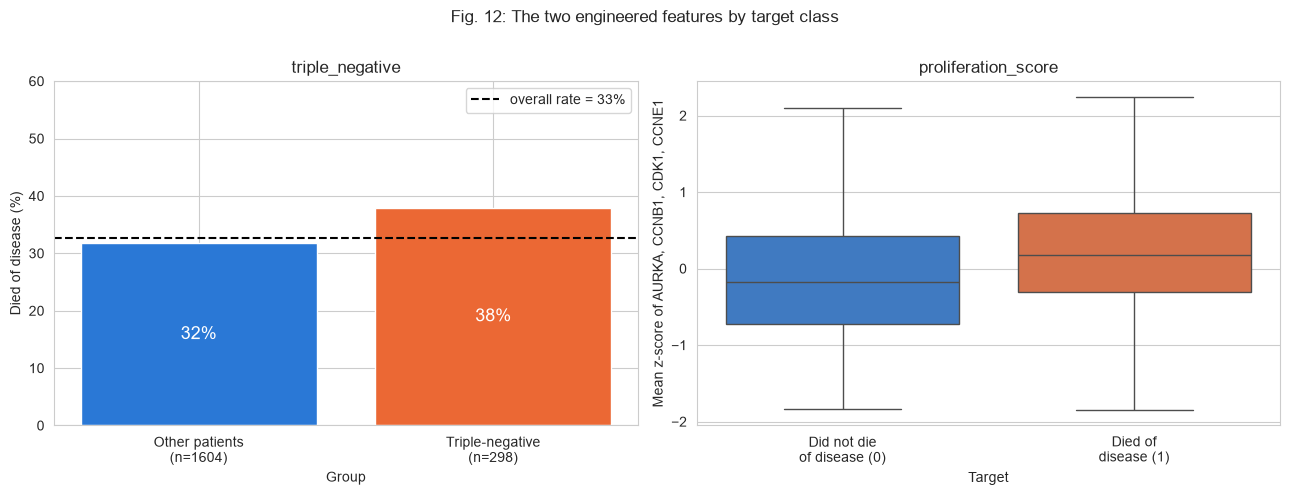

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

grp = y.groupby(X['triple_negative']).agg(['mean', 'size'])
labels = [f"{'Triple-negative' if i == 1 else 'Other patients'}\n(n={n})" for i, n in zip(grp.index, grp['size'])]
bars = axes[0].bar(labels, grp['mean'] * 100, color=[C0, C1])
axes[0].bar_label(bars, fmt='%.0f%%', label_type='center', color='white', fontsize=13)
axes[0].axhline(y.mean() * 100, color='black', linestyle='--', label=f"overall rate = {y.mean():.0%}")
axes[0].set_title('triple_negative')
axes[0].set_xlabel('Group')
axes[0].set_ylabel('Died of disease (%)')
axes[0].set_ylim(0, 60)
axes[0].legend(loc='upper right')

plot_df = pd.DataFrame({'target': y, 'proliferation_score': X['proliferation_score']})
sns.boxplot(data=plot_df, x='target', y='proliferation_score', hue='target', palette={0: C0, 1: C1},
            showfliers=False, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Did not die\nof disease (0)', 'Died of\ndisease (1)'])
axes[1].set_title('proliferation_score')
axes[1].set_xlabel('Target')
axes[1].set_ylabel('Mean z-score of AURKA, CCNB1, CDK1, CCNE1')

fig.suptitle('Fig. 12: The two engineered features by target class')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Interpretation.** Triple-negative patients died of the disease more often than the others (38% against 32%, for an overall rate of 33%). The gap is modest, but it goes in the direction expected from medical knowledge, and the group has 298 patients, which is large enough to be used. Patients who died have a higher `proliferation_score` (the box of class 1 is shifted upward in Fig. 12). Its Spearman correlation with the target is 0.20, which is similar to tumor size (0.19), and its correlation with the NPI is 0.40, so it overlaps with the NPI but is not a copy of it: it brings molecular information that the NPI does not contain.

**The rejected feature.** `n_mutated_genes` has a Spearman correlation of 0.977 with the existing column `mutation_count`, so it contains almost the same information, and its correlation with the target is only 0.05. Adding it would only create a near-duplicate column, so it is not kept. This changes one line of the plan written in the EDA, and the reason is that this check can only be done after the mutation columns are converted to 0/1.

## 4.6 Train/test split

**What the next cell does:** splits the 1,902 patients into 80% train and 20% test.
- `stratify=y` keeps the same share of class 1 in both parts. Without it, a random split could put noticeably more deaths in one part, which would make the test score unreliable.
- `random_state=SEED` makes the split identical on every run and for both team members.
- From this point on, **nothing is learned from `X_test`**.

The table checks the sizes and the class balance of each part.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

split_table = pd.DataFrame({
    'Rows': [len(X_train), len(X_test)],
    'Class 1 (died of disease)': [y_train.sum(), y_test.sum()],
    'Share of class 1': [f"{y_train.mean():.1%}", f"{y_test.mean():.1%}"],
}, index=['Train', 'Test'])
display(split_table)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

,Rows,Class 1 (died of disease),Share of class 1
Train,1521,497,32.7%
Test,381,125,32.8%


X_train: (1521, 687) | X_test: (381, 687)


**Interpretation.** The training set has 1,521 patients and the test set 381. The share of patients who died of the disease is 32.7% in train and 32.8% in test, so the stratification worked and a score on the test set will be comparable with the scores obtained by cross-validation on the training set. From this point, the test set is only used to apply what was learned on the training set.

## 4.7 Selecting the frequently mutated genes (train set only)

The EDA showed that most mutation columns are almost always 0. A gene mutated in 3 patients out of 1,500 cannot teach a model anything reliable, and 173 sparse columns would mostly add noise. We keep the genes mutated in **at least 5% of the training patients**.

**What the next cell does:** computes the mutation frequency of each gene **on `X_train` only** (the selection does not use the target, but we still apply the rule "learn on train" and be consistent), keeps the genes above 5%, and draws the frequencies of all 173 genes. Orange bars are kept, blue bars are dropped.

Genes kept (mutated in >= 5% of the training patients): 25 of 173
Top 5: PIK3CA 42%, TP53 34%, MUC16 17%, AHNAK2 16%, KMT2C 13%
Kept genes: PIK3CA, TP53, MUC16, AHNAK2, KMT2C, GATA3, SYNE1, MAP3K1, CDH1, AHNAK, DNAH11, DNAH2, USH2A, KMT2D, RYR2, DNAH5, HERC2, AKAP9, TG, PDE4DIP, TBX3, BIRC6, UTRN, ARID1A, COL6A3


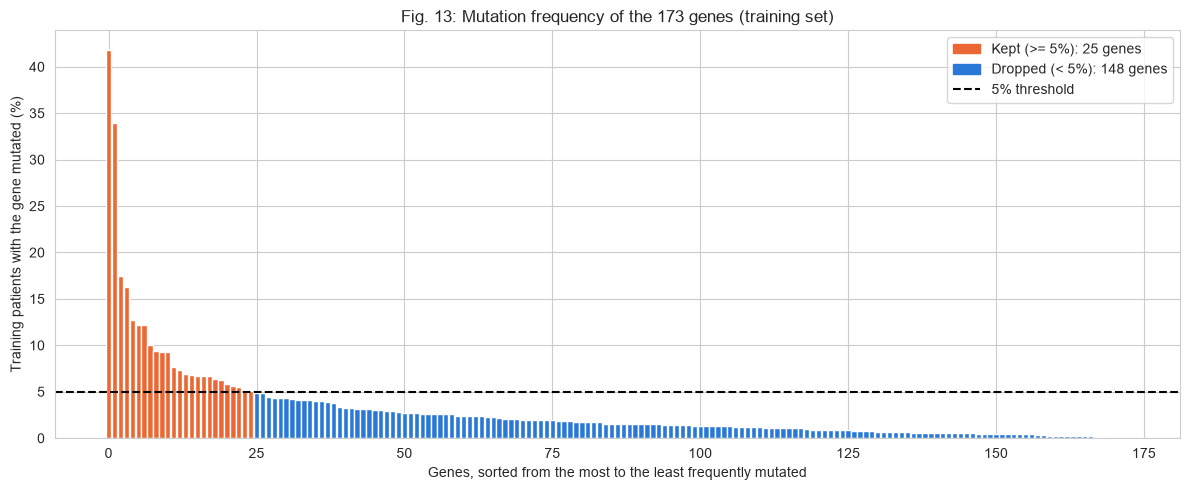

In [9]:
mut_freq = X_train[mut_cols].mean() * 100
mut_keep = mut_freq[mut_freq >= 5].sort_values(ascending=False).index.tolist()

print(f"Genes kept (mutated in >= 5% of the training patients): {len(mut_keep)} of {len(mut_cols)}")
print("Top 5:", ', '.join(f"{g.replace('_mut', '').upper()} {mut_freq[g]:.0f}%" for g in mut_keep[:5]))
print("Kept genes:", ', '.join(g.replace('_mut', '').upper() for g in mut_keep))

sorted_freq = mut_freq.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(sorted_freq)), sorted_freq.values,
       color=[C1 if v >= 5 else C0 for v in sorted_freq.values], width=0.9)
ax.axhline(5, color='black', linestyle='--')
ax.set_title('Fig. 13: Mutation frequency of the 173 genes (training set)')
ax.set_xlabel('Genes, sorted from the most to the least frequently mutated')
ax.set_ylabel('Training patients with the gene mutated (%)')
ax.legend(handles=[Patch(color=C1, label=f'Kept (>= 5%): {len(mut_keep)} genes'),
                   Patch(color=C0, label=f'Dropped (< 5%): {len(mut_cols) - len(mut_keep)} genes'),
                   plt.Line2D([0], [0], color='black', linestyle='--', label='5% threshold')])
plt.tight_layout()
plt.show()

**Interpretation.** 25 genes pass the 5% threshold, the same number as in the EDA, where the frequency was computed on all patients, so the selection is stable. PIK3CA (42%) and TP53 (34%) stand out, then the frequency decreases smoothly. There is no natural break near 5% (the next gene is at about 4.9%), so the threshold is a convention and not a discovery. We keep it because a gene mutated in less than 5% of the training patients (fewer than about 76 patients) gives the models too few examples, and 148 almost-empty columns would mostly add noise. The threshold could be tested as a hyperparameter in Phase 7.

## 4.8 Missing values before the pipeline

**What the next cell does:** lists the columns of the training set that still contain missing values after the cleaning, and draws them as horizontal bars. These are the gaps the pipeline must fill. The gene-expression, mutation and engineered columns are complete.

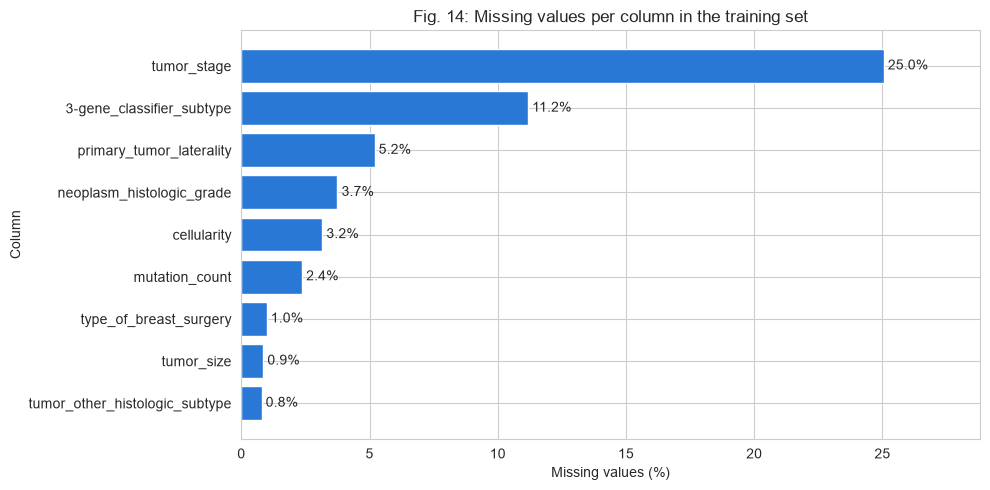

Columns with missing values: 9 of 687
Training rows with at least one missing value: 41.6%
Missing values outside these columns: 0


In [10]:
missing_train = X_train.isna().mean() * 100
missing_train = missing_train[missing_train > 0].sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(missing_train.index, missing_train.values, color=C0)
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_title('Fig. 14: Missing values per column in the training set')
ax.set_xlabel('Missing values (%)')
ax.set_ylabel('Column')
ax.set_xlim(0, missing_train.max() * 1.15)
plt.tight_layout()
plt.show()

print(f"Columns with missing values: {len(missing_train)} of {X_train.shape[1]}")
print(f"Training rows with at least one missing value: {X_train.isna().any(axis=1).mean():.1%}")
print(f"Missing values outside these columns: {X_train.drop(columns=missing_train.index).isna().sum().sum()}")

**Interpretation.** Nine columns have gaps. `tumor_stage` is the main problem (25.0%), followed by `3-gene_classifier_subtype` (11.2%), and every other column is at 5.2% or below. In total 41.6% of the training rows have at least one gap, so dropping incomplete rows would remove about 4 patients out of 10, which is why the gaps are imputed. The 489 gene columns, the mutation flags and the engineered features are complete.

## 4.9 Column groups

A pipeline treats each kind of column differently, so every column must belong to exactly one group.

**What the next cell does:** defines the five groups **by column name** (not by data type, because pandas stores text as `str` and some mutation columns as integers).

| Group | Content | Treatment |
|---|---|---|
| `num` | Clinical numbers, grade, gene expression, `proliferation_score` | Median imputation, then standardisation |
| `stage` | `tumor_stage` (0 to 4, 26% missing) | Median imputation **plus a missing-value indicator**, then standardisation |
| `ord` | `cellularity` (Low < Moderate < High) | Most-frequent imputation, then ordinal code |
| `nom` | Nominal and binary text columns | Most-frequent imputation, then one-hot encoding |
| `bin` | Treatments, `triple_negative`, kept mutation flags | Unchanged (already 0/1, no gaps) |

The grade and the stage are already ordered numbers, so they stay numerical: this keeps their order without any encoder. The `assert` checks that no column was forgotten, because the `ColumnTransformer` silently drops a column that is not in any group.

In [11]:
num_cols = ['age_at_diagnosis', 'tumor_size', 'lymph_nodes_examined_positive', 'mutation_count',
            'nottingham_prognostic_index', 'neoplasm_histologic_grade', 'proliferation_score'] + expr_cols
stage_col = ['tumor_stage']
ord_col = ['cellularity']
nom_cols = ['type_of_breast_surgery', 'er_status', 'her2_status', 'pr_status',
            'inferred_menopausal_state', 'primary_tumor_laterality', 'pam50_+_claudin-low_subtype',
            'cohort', 'her2_status_measured_by_snp6', 'tumor_other_histologic_subtype',
            'integrative_cluster', '3-gene_classifier_subtype']
bin_cols = ['chemotherapy', 'hormone_therapy', 'radio_therapy', 'triple_negative'] + mut_keep

groups = [('num', num_cols), ('stage', stage_col), ('ord', ord_col), ('nom', nom_cols), ('bin', bin_cols)]
all_used = [c for _, cols in groups for c in cols]

assert len(all_used) == len(set(all_used)), "a column is in two groups"
assert set(X.columns) - set(all_used) == set(mut_cols) - set(mut_keep), "a column was forgotten"
assert X_train[bin_cols].isna().sum().sum() == 0, "the bin group must have no missing values"

group_table = pd.DataFrame({
    'Group': [g for g, _ in groups],
    'Columns': [len(c) for _, c in groups],
    'Missing cells in train': [int(X_train[c].isna().sum().sum()) for _, c in groups],
    'First columns': [', '.join(c[:3]) for _, c in groups],
})
display(group_table)
print(f"Columns used: {len(all_used)} | columns dropped (rare mutations): {len(mut_cols) - len(mut_keep)}")

,Group,Columns,Missing cells in train,First columns
0,num,496,106,"age_at_diagnosis, tumor_size, lymph_nodes_examined_positive"
1,stage,1,381,tumor_stage
2,ord,1,48,cellularity
3,nom,12,276,"type_of_breast_surgery, er_status, her2_status"
4,bin,29,0,"chemotherapy, hormone_therapy, radio_therapy"


Columns used: 539 | columns dropped (rare mutations): 148


**Interpretation.** Every column is in exactly one group: 539 columns are used and 148 rare-mutation columns are dropped on purpose, which the `assert` verifies. Most of the gaps are in `tumor_stage` (381 cells) and in the nominal group (276 cells). The numerical group has only 106 gaps in 496 columns because the gene columns are complete. The `bin` group has no gap, so it can pass through unchanged.

## 4.10 The preprocessing pipeline

**What the next cell does:** defines `make_preprocessor()`, a function that builds the `ColumnTransformer`. It is a function, and not a single object, because section 4.14 needs the same preprocessing on three different sets of columns.
- Each block is a small `Pipeline`: first the imputer, then the scaler or the encoder.
- `SimpleImputer(strategy='median', add_indicator=True)` adds one extra column that is 1 where `tumor_stage` was missing. The fact that the stage was not recorded can itself be informative. The scaler that follows also standardises this indicator column, which does not change its information.
- `OneHotEncoder(handle_unknown='ignore')` gives all zeros if the test set contains a category never seen in training, instead of crashing.
- `OrdinalEncoder(categories=...)` fixes the order Low < Moderate < High explicitly, otherwise it would sort alphabetically (High, Low, Moderate).
- `set_output(transform='pandas')` makes the result a DataFrame with named columns, which is easier to inspect.
- `set_config(display='diagram')` shows the pipeline as a diagram: click on a block to expand it.

In [12]:
def make_preprocessor(keep=None):
    # keep = set of column names to use; None means all the columns
    def pick(cols):
        return cols if keep is None else [c for c in cols if c in keep]

    blocks = [
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), pick(num_cols)),
        ('stage', Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                            ('scaler', StandardScaler())]), pick(stage_col)),
        ('ord', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OrdinalEncoder(categories=[['Low', 'Moderate', 'High']]))]), pick(ord_col)),
        ('nom', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), pick(nom_cols)),
        ('bin', 'passthrough', pick(bin_cols)),
    ]
    ct = ColumnTransformer([b for b in blocks if len(b[2]) > 0], remainder='drop')
    return ct.set_output(transform='pandas')

set_config(display='diagram')
preprocessor = make_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('stage', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

## 4.11 Fitting on the training set and transforming both sets

**What the next cell does:** applies the pipeline.
- `fit_transform(X_train)` **learns** the medians, the means, the standard deviations and the categories on the training patients, then transforms them.
- `transform(X_test)` only **applies** what was learned. It never looks at the test patients to compute anything.

It prints the shape before and after, and checks that no missing value remains. The table shows how many output columns each group produces.

In [13]:
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)

print(f"Train: {X_train.shape} -> {Xt_train.shape}")
print(f"Test : {X_test.shape} -> {Xt_test.shape}")
print(f"Missing values after the pipeline: train = {int(Xt_train.isna().sum().sum())}, test = {int(Xt_test.isna().sum().sum())}")

out_groups = pd.Series([c.split('__')[0] for c in Xt_train.columns]).value_counts()
before_after = pd.DataFrame({
    'Columns before': [len(c) for _, c in groups],
    'Columns after': [out_groups[g] for g, _ in groups],
}, index=[g for g, _ in groups])
before_after.loc['Total'] = before_after.sum()
display(before_after)

display(Xt_train.filter(regex='^(stage|ord|bin__chemo|nom__er_status)').head(5).round(2))

Train: (1521, 687) -> (1521, 579)
Test : (381, 687) -> (381, 579)
Missing values after the pipeline: train = 0, test = 0


,Columns before,Columns after
num,496,496
stage,1,2
ord,1,1
nom,12,51
bin,29,29
Total,539,579


,stage__tumor_stage,stage__missingindicator_tumor_stage,ord__cellularity,nom__er_status_Negative,nom__er_status_Positive,bin__chemotherapy
1513,0.33,1.73,1.0,0.0,1.0,0
1291,0.33,-0.58,2.0,1.0,0.0,0
1485,0.33,1.73,2.0,0.0,1.0,0
765,-1.47,-0.58,2.0,1.0,0.0,0
356,-3.26,-0.58,0.0,1.0,0.0,0


**Interpretation.** The pipeline turns 687 columns into 579 and removes every missing value in both sets. The number of columns grows for two groups only: one-hot encoding turns the 12 nominal columns into 51 (one column per category), and the stage block receives its missing-value indicator. The indicator is standardised, so it shows two values (1.73 and -0.58) instead of 1 and 0, which is the same information on another scale. The test set has exactly the same 579 columns as the training set.

## 4.12 Proof that the test set was not used

**What the next cell does:** compares what the pipeline learned from the training set with what it would have learned from all patients.
- The table shows, for three columns, the median used to fill the gaps and the mean used by the scaler. **Used** = learned on the training set (what the pipeline really does). **Leaky** = computed on all 1,902 patients (what a pipeline fitted before the split would do).
- The second print shows the mean of the standardised columns: it is 0 for the training set **by construction**, and not exactly 0 for the test set, which proves that the test patients did not take part in the fitting.
- Fig. 15 shows `tumor_size` before and after the pipeline (training set).

,"Median, used","Median, leaky","Mean for scaling, used","Mean for scaling, leaky"
tumor_size,22.75,23.00,26.143,26.212
age_at_diagnosis,61.72,61.78,60.974,61.093
mutation_count,5.00,5.00,5.716,5.679


Largest |mean| of a standardised column, train: 4.2e-16
Largest |mean| of a standardised column, test : 0.21


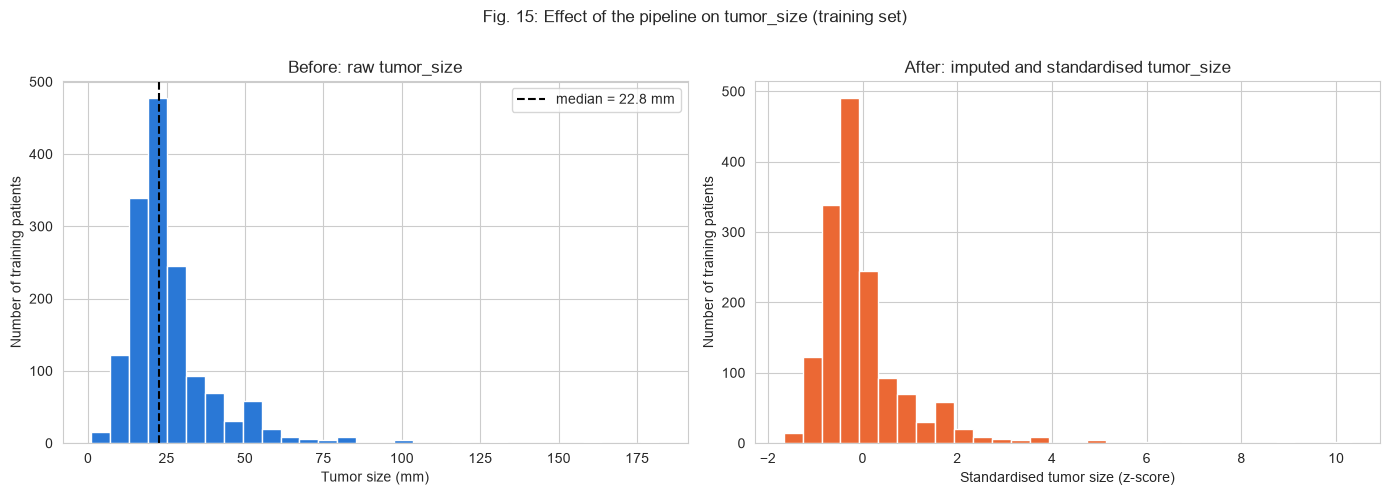

In [14]:
imputer_num = preprocessor.named_transformers_['num'].named_steps['imputer']
scaler_num = preprocessor.named_transformers_['num'].named_steps['scaler']
check_cols = ['tumor_size', 'age_at_diagnosis', 'mutation_count']

used_median = pd.Series(imputer_num.statistics_, index=num_cols)[check_cols]
used_mean = pd.Series(scaler_num.mean_, index=num_cols)[check_cols]
leaky_median = X[check_cols].median()
leaky_mean = X[check_cols].fillna(leaky_median).mean()

display(pd.DataFrame({
    'Median, used': used_median, 'Median, leaky': leaky_median,
    'Mean for scaling, used': used_mean, 'Mean for scaling, leaky': leaky_mean,
}).round(3))

num_out = [c for c in Xt_train.columns if c.startswith('num__')]
print(f"Largest |mean| of a standardised column, train: {Xt_train[num_out].mean().abs().max():.1e}")
print(f"Largest |mean| of a standardised column, test : {Xt_test[num_out].mean().abs().max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(X_train['tumor_size'].dropna(), bins=30, color=C0, edgecolor='white')
axes[0].axvline(used_median['tumor_size'], color='black', linestyle='--', label=f"median = {used_median['tumor_size']:.1f} mm")
axes[0].set_title('Before: raw tumor_size')
axes[0].set_xlabel('Tumor size (mm)')
axes[0].set_ylabel('Number of training patients')
axes[0].legend()

axes[1].hist(Xt_train['num__tumor_size'], bins=30, color=C1, edgecolor='white')
axes[1].set_title('After: imputed and standardised tumor_size')
axes[1].set_xlabel('Standardised tumor size (z-score)')
axes[1].set_ylabel('Number of training patients')

fig.suptitle('Fig. 15: Effect of the pipeline on tumor_size (training set)')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Interpretation.** The medians and means that the pipeline uses (learned on the training set) are slightly different from those computed on all patients, for example a median tumor size of 22.75 mm instead of 23.00 mm. The differences are small here because the training set is large, but they are real, and they would carry information from the test patients into the training if the fitting were done before the split. The standardised training columns have a mean of 4.2e-16 (zero by construction), while the test columns reach 0.21: the test patients were transformed with the training values only, as intended.

In Fig. 15 the standardisation moves and rescales the distribution but does not change its shape: the right skew stays, and the largest tumor (182 mm) is about 10 standard deviations above the mean. These extreme values are kept on purpose (they are plausible, and tree models are not sensitive to them). Scaling matters for Logistic Regression, KNN and SVM, and is harmless for trees.

## 4.13 Class imbalance

The EDA found a moderate imbalance (about 2 to 1). The decision was to use **class weights**, which are an option of the models and not a transformation of the data, so they are applied in Phase 5.

**What the next cell does:** computes, on the training labels only, the two values the models will need.
- `class_weight`: the weight of each class, so that errors on the rare class (death from the disease) cost more. This is what `class_weight='balanced'` does in Logistic Regression and Random Forest.
- `scale_pos_weight`: the ratio class 0 / class 1. XGBoost and LightGBM use this single number instead of a dictionary.

In [15]:
classes = np.array([0, 1])
weights = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight = dict(zip(classes.tolist(), weights.round(3).tolist()))
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f"class_weight = {class_weight}")
print(f"scale_pos_weight = {scale_pos_weight:.3f}")

class_weight = {0: 0.743, 1: 1.53}
scale_pos_weight = 2.060


**Interpretation.** `class_weight = {0: 0.743, 1: 1.53}` means that a mistake on a patient who died of the disease counts about twice as much (1.53 / 0.743 = 2.06) as a mistake on another patient. `scale_pos_weight = 2.06` is the same ratio as a single number for XGBoost and LightGBM. Both are computed on the training labels only.

We prefer class weights to SMOTE. SMOTE creates synthetic patients by interpolating between real ones, and with 579 columns, many of them 0/1 or one-hot, the synthetic rows would contain impossible values (for example half a category). The imbalance is only moderate. One point for Phase 5: KNN has no `class_weight` option, so for this model the imbalance will be handled through the metrics (AUC, F1, recall of class 1) and the decision threshold.

## 4.14 Three feature sets for the central question

Our question compares three kinds of information: the NPI that oncologists use, clinical data, and clinical data plus molecular data. Phase 5 will train the same models on each set, so the sets are defined now.

**What the next cell does:** defines three **nested** sets, each one containing the previous one, so that any improvement can be attributed to the information added.
- **A. NPI only:** the single score `nottingham_prognostic_index`.
- **B. Clinical:** all clinical columns, including the NPI and the engineered `triple_negative`.
- **C. Clinical + genes + mutations:** B plus the 489 gene-expression columns, `proliferation_score` and the kept mutation flags. This is the full pipeline of section 4.10.

For each set it builds a preprocessor with `make_preprocessor(keep=...)`, fits it on the training set and reports the number of columns before and after.

In [16]:
clinical_features = [c for c in X.columns if c not in expr_cols and c not in mut_cols and c != 'proliferation_score']
omics_features = expr_cols + ['proliferation_score'] + mut_keep

feature_sets = {
    'A. NPI only': ['nottingham_prognostic_index'],
    'B. Clinical': clinical_features,
    'C. Clinical + genes + mutations': clinical_features + omics_features,
}

rows = []
for name, cols in feature_sets.items():
    pre = make_preprocessor(keep=set(cols))
    Xt = pre.fit_transform(X_train)
    rows.append({'Feature set': name, 'Columns before': len(cols), 'Columns after': Xt.shape[1]})
display(pd.DataFrame(rows).set_index('Feature set'))

assert make_preprocessor(keep=set(feature_sets['C. Clinical + genes + mutations'])).fit_transform(X_train).shape == Xt_train.shape

,Columns before,Columns after
Feature set,,
A. NPI only,1,1
B. Clinical,24,64
C. Clinical + genes + mutations,539,579


**Interpretation.** The three sets are nested (A inside B inside C). Set A has one column. Set B grows from 24 to 64 columns after one-hot encoding. Set C has 579 columns and is identical to the full pipeline of section 4.10, which the `assert` confirms. In Phase 5 the same models will be trained on each set: the comparison between A and B shows whether a model that uses the clinical data beats the NPI formula, and the comparison between B and C answers the central question, whether genes and mutations add information beyond the clinical data.

**Decision.** Set B keeps the NPI, because a doctor who has the clinical data also has the NPI: the fair question is whether the other clinical variables add anything to it. In Phase 5, set A is evaluated as the raw NPI score, without a model: ROC-AUC depends only on how the patients are ranked, and the NPI is already a risk score.

## 4.15 Final checks

**What the next cell does:** verifies automatically the rules of this notebook. If one `assert` fails, the notebook stops, which is better than discovering a leak at the defense.
- No leakage or redundant column is left in `X`.
- Train and test do not share any patient.
- Train and test have the same columns and no missing value after the pipeline.
- The share of class 1 is the same in train and test (stratification).
- No output column name contains a character that XGBoost or LightGBM refuse in feature names (checked now to avoid a surprise in Phase 5).

In [17]:
assert not set(leakage_cols + redundant_cols) & set(X.columns)
assert not set(X_train.index) & set(X_test.index)
assert list(Xt_train.columns) == list(Xt_test.columns)
assert Xt_train.isna().sum().sum() == 0 and Xt_test.isna().sum().sum() == 0
assert abs(y_train.mean() - y_test.mean()) < 0.005

forbidden = set('[]<>{}",:')
bad_names = [c for c in Xt_train.columns if forbidden & set(c)]
print(f"Output column names with a forbidden character: {len(bad_names)}")
if bad_names:
    print(bad_names)
print("All checks passed.")

Output column names with a forbidden character: 0
All checks passed.


## 4.16 Saving the cleaned dataset

**What the next cell does:** saves the cleaned table (after sections 4.2 to 4.5, **before** the split, imputation and scaling) in `data/processed/`, with the target as the last column. The raw file in `data/raw/` is never modified. The file is committed to the repository, because `03_modeling.ipynb` starts by loading it. Because the split uses `random_state=42`, the next notebooks can rebuild exactly the same train and test sets from this file.

In [18]:
os.makedirs('../data/processed', exist_ok=True)
clean = X.copy()
clean['target'] = y
clean.to_csv('../data/processed/metabric_clean.csv', index=False)
print(f"Saved: ../data/processed/metabric_clean.csv {clean.shape}")

Saved: ../data/processed/metabric_clean.csv (1902, 688)


## 4.17 Summary of the preprocessing decisions

| Step | Choice | Justification | Alternative rejected |
|---|---|---|---|
| Rows | Drop 2 patients (no target, sarcoma) | Unknown class; a different disease | Keep them: they cannot be used or taught |
| Leakage columns | Drop `patient_id`, `overall_survival`, `overall_survival_months`, `death_from_cancer` | Known only after the outcome | Keep them: inflated score, useless model |
| Redundant columns | Drop 4 columns | Same information as a kept column | Keep them: duplicated information |
| Mutations | 0/1 flags, keep the 25 genes mutated in at least 5% of the training patients | Extremely sparse columns; too few examples for rare genes | Keep all 173; keep the exact codes |
| Engineered features | `triple_negative`, `proliferation_score` | Domain knowledge, checked in Fig. 12 | `n_mutated_genes`: correlation 0.977 with `mutation_count`; `treatment_count`: adding up three different treatments loses which one was given, and the three treatments are already features |
| Split | 80/20, stratified, seed 42 | Same class share in train and test; reproducible | Random split without stratification |
| Missing values | Median (numbers) and most frequent (text) inside the pipeline, plus an indicator for `tumor_stage` | 41.6% of the rows have a gap; the median resists skewed values | Drop rows; mean imputation |
| Encoding | `OrdinalEncoder` for `cellularity`; one-hot for nominal columns; grade and stage stay numerical | Keeps the order where there is one, and creates no false order elsewhere | `LabelEncoder` or one-hot for everything |
| Scaling | `StandardScaler` on numerical columns | Needed by Logistic Regression, KNN and SVM; harmless for trees | `MinMaxScaler` (sensitive to the extreme tumors) |
| Outliers | Kept | Plausible values; tree models are robust | Removal |
| Imbalance | Class weights (`class_weight`, `scale_pos_weight`) in Phase 5 | Moderate imbalance; SMOTE would create impossible synthetic rows | SMOTE; under-sampling |
| Feature sets | A (NPI) inside B (clinical) inside C (clinical + genes + mutations) | Needed for the central question | One single set |

## Output of Phase 4
- The full pipeline turns 687 columns into **579 numerical columns** with no missing value, for 1,521 training and 381 test patients.
- `make_preprocessor(keep=...)` builds the same preprocessing for the three feature sets (A: 1 column, B: 64, C: 579).
- The cleaned dataset is saved in `data/processed/metabric_clean.csv`.

## Limits and points for Phase 5
- **Cross-validation:** in Phase 5, `make_preprocessor()` must be the **first step of the `Pipeline`**, and `cross_val_score` must receive the raw `X_train`. If the models are given the already transformed `Xt_train`, the imputer and the scaler are fitted once on all the training rows, so each validation fold has influenced them (a small leak inside the cross-validation).
- The list of 25 frequent genes is computed once on the whole training set, not inside each fold. It does not use the target, so the effect is small, but it should be mentioned in the report.
- The four genes of `proliferation_score` were partly chosen from the EDA, which saw all patients, including the test set. The effect on the test score should be very small, because the score is the mean of four columns that set C already contains, but it is stated in the report.
- The binary target ignores the follow-up time (a limitation already noted in the EDA).
- `tumor_stage` has 25% of gaps filled by the median, with an indicator. A model-based imputation (for example KNN imputation) could be compared later.

## Next step
Phase 5: train at least four baseline models (Logistic Regression, KNN, Random Forest, XGBoost or LightGBM) on the three feature sets with 5-fold cross-validation.